In [1]:
# Importing Libraries
import ast
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt  

# Loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

In [5]:
df[['job_title_short' , 'job_skills']].head()

,job_title_short,job_skills
0,Senior Data Engineer,NaN
1,Data Analyst,"[r, python, sql, nosql, power bi, tableau]"
2,Data Engineer,"[python, sql, c#, azure, airflow, dax, docker,..."
3,Data Engineer,"[python, c++, java, matlab, aws, tensorflow, k..."
4,Data Engineer,"[bash, python, oracle, aws, ansible, puppet, j..."


In [7]:
dfl= df.copy() 

In [ ]:
# Explode job_skills column
dfl_skills = dfl.explode('job_skills')
dfl_skills['job_skills']

0                NaN
1                  r
1             python
1                sql
1              nosql
             ...    
785739         kafka
785739    kubernetes
785739        docker
785740           aws
785740          flow
Name: job_skills, Length: 3777320, dtype: str

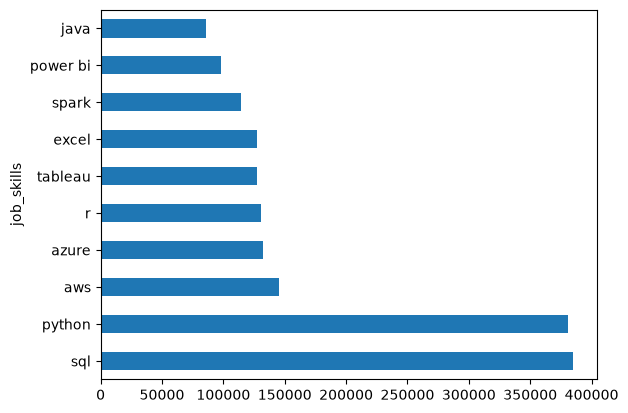

In [15]:
dfl_skills['job_skills'].value_counts().head(10).plot(kind ='barh')
plt.show()

In [20]:
# Group by job_skills and job_title_short and count the number of occurrences
skills_count = dfl_skills.groupby(['job_title_short', 'job_skills']).size()

In [22]:
skills_count

job_title_short    job_skills
Business Analyst   airflow        318
                   airtable        17
                   alteryx       1078
                   angular         87
                   ansible        120
                                 ... 
Software Engineer  wrike            4
                   wsl             13
                   xamarin         35
                   yarn           145
                   zoom           229
Length: 2256, dtype: int64

In [28]:
#convert the serie to data frame  
dfl_skills_count = skills_count.reset_index(name = 'skill_count') #Name the count column as count
dfl_skills_count = dfl_skills_count.sort_values(by ='skill_count', ascending = False)
dfl_skills_count

,job_title_short,job_skills,skill_count
1066,Data Scientist,python,113711
865,Data Engineer,sql,113130
830,Data Engineer,python,108022
625,Data Analyst,sql,92428
1101,Data Scientist,sql,78982
...,...,...,...
462,Data Analyst,chainer,1
432,Cloud Engineer,wrike,1
410,Cloud Engineer,theano,1
24,Business Analyst,chainer,1


In [34]:
job_title = 'Data Analyst'
top_skills = 15
dfl_skills_DA = dfl_skills_count[dfl_skills_count['job_title_short'] == job_title].head(top_skills)
dfl_skills_DA 

,job_title_short,job_skills,skill_count
625,Data Analyst,sql,92428
494,Data Analyst,excel,66860
590,Data Analyst,python,57190
638,Data Analyst,tableau,46455
583,Data Analyst,power bi,39380
594,Data Analyst,r,29996
606,Data Analyst,sas,27998
585,Data Analyst,powerpoint,13822
664,Data Analyst,word,13562
605,Data Analyst,sap,11280


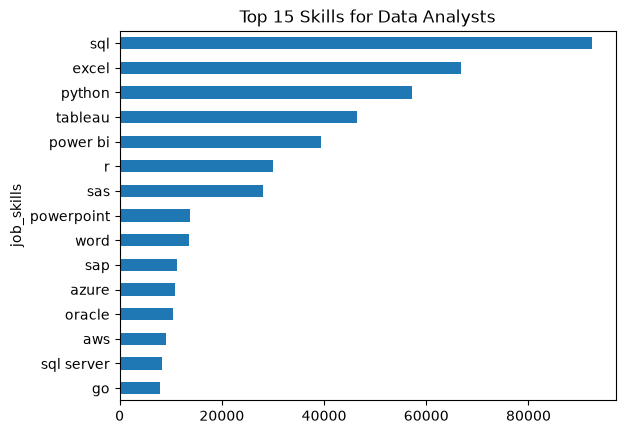

In [48]:
dfl_skills_DA.plot(kind = 'barh', x = 'job_skills' , y ='skill_count')
plt.title(f'Top {top_skills} Skills for {job_title}s')
plt.xlabel('')
plt.gca().invert_yaxis()
plt.legend().set_visible(False)
plt.show()